##EDS 6352 - Natural Language Processing

##HW1



In [ ]:
import kagglehub

# Download latest version
path = kagglehub.dataset_download("yasserh/imdb-movie-ratings-sentiment-analysis")

print("Path to dataset files:", path)

100%|██████████| 20.6M/20.6M [00:00<00:00, 92.4MB/s]

Extracting files...


Path to dataset files: /root/.cache/kagglehub/datasets/yasserh/imdb-movie-ratings-sentiment-analysis/versions/1


In [1]:
import pandas as pd
import re
import spacy
from collections import Counter
import math
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

In [2]:
df = pd.read_csv("movie.csv")
df.head()

,text,label
0,I grew up (b. 1965) watching and loving the Th...,0
1,"When I put this movie in my DVD player, and sa...",0
2,Why do people who do not know what a particula...,0
3,Even though I have great interest in Biblical ...,0
4,Im a die hard Dads Army fan and nothing will e...,1


In [3]:
print('size of the dataset:', df.size)
print('rows and columns:', df.shape)

size of the dataset: 80000
rows and columns: (40000, 2)


In [4]:
df.isna().any()

,0
text,False
label,False


Comment: There is no missing data in the dataset.

Random sampling the dataset for training and testing data.

In [5]:
df.duplicated().sum()

np.int64(277)

In [6]:
df = df.drop_duplicates()
df.shape

(39723, 2)

Comment: Dropping the duplicates in the dataset.

In [4]:
"""
Using the sample method provided by the pandas dataframe that randomly samples 1000 data points.
A random_state value is provided for reproducibility.
"""
train_samples = df.sample(n=1000, random_state=42)
# dropping the samples from the dataset that were selected for training, so test samples can be unseen.
remaining_df = df.drop(train_samples.index)
# grouping the data by labels, and picking 200 samples from the data to make sure classes balance is equal.
test_samples = remaining_df.groupby('label').sample(n=200, random_state=42)

In [8]:
train_samples['text'].nunique()
# verifies that we have 1000 unique data points, and each point was picked without replacement.

1000

In [9]:
train_samples['label'].value_counts()

,count
label,
1,504
0,496


In [10]:
test_samples['label'].value_counts()

,count
label,
0,200
1,200


In [11]:
train_samples.shape

(1000, 2)

In [12]:
test_samples.shape

(400, 2)

Comment: Verifying the shape of the training and the testing data as specified in the assignment.

In [3]:
nlp = spacy.load("en_core_web_sm")

NEGATION_WORDS = {"not", "n't", "never", "no", "none", "nobody",
                   "nothing", "neither", "nowhere", "cannot", "without"}

In [5]:
def preprocess_text(text, lemmatize_words=True, remove_stop_words=True, handle_logical_negation=True):

    if handle_logical_negation and not lemmatize_words:
        raise ValueError("handle_logical_negation requires lemmatize_words=True")

    # --- Step 1: regex cleanup ---
    text = re.sub(r'<[^>]+>', '. ', text)                          # tags -> sentence break
    text = re.sub(r"[^a-zA-Z0-9\s.,!?;:'\"()\-]", ' ', text)       # drop junk symbols, keep punctuation
    text = re.sub(r'\s+', ' ', text).strip()                       # collapse whitespace

    # --- Step 2: parse with spaCy ---
    doc = nlp(text)

    # --- Step 3: mark negation scope ---
    negate_flags = [False] * len(doc)
    if handle_logical_negation:
        negating = False
        for i, token in enumerate(doc):
            if token.is_punct:
                negating = False           # punctuation ends the scope
                continue
            if token.lower_ in NEGATION_WORDS or token.dep_ == "neg":
                negating = True            # cue word itself isn't tagged
                continue
            negate_flags[i] = negating

    # --- Step 4: assemble final tokens ---
    result = []
    for i, token in enumerate(doc):
        # checks for punctuation
        if token.is_punct or token.is_space:
            continue
        # checks for stop words here
        if remove_stop_words and token.is_stop:
            continue

        # checks for lemma here.
        word = token.lemma_.lower() if lemmatize_words else token.text.lower()
        if negate_flags[i]:
            word = "NOT_" + word

        result.append(word)

    return " ".join(result)

###Building Naive Bayes Classifier

In [6]:
def train_naive_bayes(train_df, text_col="clean_text", label_col="label"):
    classes = train_df[label_col].unique()
    priors = {}
    word_counts = {}   # class -> Counter(word -> count)
    class_totals = {}  # class -> total word count in that class
    vocab = set()

    for c in classes:
        subset = train_df[train_df[label_col] == c]
        # Calculating the prior probability for each class.
        priors[c] = len(subset) / len(train_df)

        # in counts keeping track of all the words in the dataset. Maintaining the word count, and also the total vocab for the dataset.
        counts = Counter()
        for text in subset[text_col]:
            words = text.split()
            counts.update(words)
            vocab.update(words)

        word_counts[c] = counts
        class_totals[c] = sum(counts.values())

    return priors, word_counts, class_totals, vocab

In [7]:
def predict(text, priors, word_counts, class_totals, vocab):
    # removes any unknown words.
    words = [w for w in text.split() if w in vocab]
    V = len(vocab)

    scores = {}
    for c in priors:
        # calculating prior log.
        log_prob = math.log(priors[c])
        for w in words:
            count = word_counts[c][w]  # 0 if unseen for this class
            # 1 is added to the count for laplace smoothing.
            likelihood = (count + 1) / (class_totals[c] + V)
            # adding the log of likelihood.
            log_prob += math.log(likelihood)
        scores[c] = log_prob

    return max(scores, key=scores.get)

In [8]:
def evaluate(actual, predicted, classes):
    # confusion matrix as a dict: (actual_class, predicted_class) -> count
    matrix = {(a, p): 0 for a in classes for p in classes}
    for a, p in zip(actual, predicted):
        matrix[(a, p)] += 1

    print("Confusion Matrix (rows=actual, cols=predicted)")
    print("        " + "  ".join(f"pred={c}" for c in classes))
    for a in classes:
        row = [matrix[(a, p)] for p in classes]
        print(f"actual={a}  " + "  ".join(str(v) for v in row))
    print()

    metrics = {}
    for c in classes:
        TP = matrix[(c, c)]
        FP = sum(matrix[(a, c)] for a in classes if a != c)
        FN = sum(matrix[(c, p)] for p in classes if p != c)

        precision = TP / (TP + FP) if (TP + FP) > 0 else 0
        recall = TP / (TP + FN) if (TP + FN) > 0 else 0
        f1 = 2 * precision * recall / (precision + recall) if (precision + recall) > 0 else 0

        metrics[c] = {"precision": precision, "recall": recall, "f1": f1}
        print(f"Class {c}: precision={precision:.3f}  recall={recall:.3f}  f1={f1:.3f}")

    accuracy = sum(matrix[(c, c)] for c in classes) / len(actual)
    print(f"\nOverall accuracy: {accuracy:.3f}")

    return matrix, metrics

###Scenario 1: Without lemmatization, removal of stop words, or handling logical negation

In [21]:
# creating the copy of the original training data for the first scenario.
train_scenario_1 = train_samples.copy()
test_scenario_1 = test_samples.copy()

In [11]:
# using the lambda function, applying the preprocess text function on all data points in the "text" column, storing the result in "clean_text" column.
train_scenario_1["clean_text"] = train_samples["text"].apply(
    lambda x: preprocess_text(x, lemmatize_words=False,
                                  remove_stop_words=False,
                                  handle_logical_negation=False)
)

In [12]:
test_scenario_1["clean_text"] = test_samples["text"].apply(
    lambda x: preprocess_text(x, lemmatize_words=False,
                                  remove_stop_words=False,
                                  handle_logical_negation=False)
)

In [13]:
train_scenario_1['clean_text'].iloc[0]

"the central theme in this movie seems to be confusion as the relationships setting acting and social context all lead to the same place confusion even harvey keitel appears to be out of his element and lacks his usual impeccable clarity direction and intensity to make matters worse his character 's name is che and we are only told directly by the narrator well into the film that he is not that che just a guy named che the family relationships remain unclear until the end of the film and once defined the family is divided the younger generation off to america so clich other reviews discuss how the movie depicts the impact of the revolution on a boy 's family however the political stance of the director is murky at best and we are never quite sure who is responsible for what bloodshed so they lost their property acquired by gambling profits so what refusing to take a political stand when making a movie about the cuban revolution is an odd and cowardly choice not to mention the movie was

Comment: Verifying what the output looks like from the preprocess function.

In [14]:
priors, word_counts, class_totals, vocab = train_naive_bayes(train_scenario_1, text_col="clean_text", label_col="label")

In [93]:
class_totals

{np.int64(0): 49029, np.int64(1): 52507}

In [15]:
test_scenario_1["predicted"] = test_scenario_1["clean_text"].apply(
    lambda x: predict(x, priors, word_counts, class_totals, vocab)
)

In [17]:
matrix, metrics = evaluate(test_scenario_1['label'], test_scenario_1['predicted'], [0,1])

Confusion Matrix (rows=actual, cols=predicted)
        pred=0  pred=1
actual=0  172  28
actual=1  55  145

Class 0: precision=0.758  recall=0.860  f1=0.806
Class 1: precision=0.838  recall=0.725  f1=0.777

Overall accuracy: 0.792


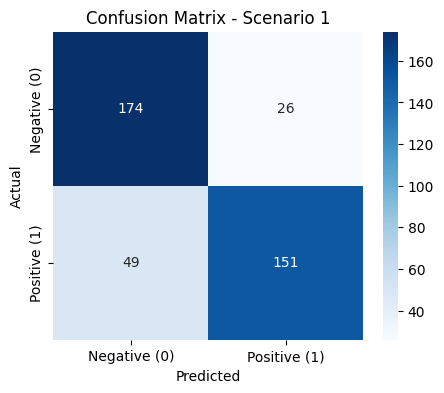

In [59]:
cm = np.array([[matrix[(0,0)], matrix[(0,1)]],
               [matrix[(1,0)], matrix[(1,1)]]])

plt.figure(figsize=(5, 4))
sns.heatmap(cm, annot=True, fmt="d", cmap="Blues",
            xticklabels=["Negative (0)", "Positive (1)"],
            yticklabels=["Negative (0)", "Positive (1)"])
plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.title("Confusion Matrix - Scenario 1")
plt.show()

###Scenario 2: With lemmatization only

In [60]:
train_scenario_2 = train_samples.copy()
test_scenario_2 = test_samples.copy()

In [61]:
train_scenario_2["clean_text"] = train_samples["text"].apply(
    lambda x: preprocess_text(x, lemmatize_words=True,
                                  remove_stop_words=False,
                                  handle_logical_negation=False)
)

In [62]:
test_scenario_2["clean_text"] = test_samples["text"].apply(
    lambda x: preprocess_text(x, lemmatize_words=True,
                                  remove_stop_words=False,
                                  handle_logical_negation=False)
)

In [87]:
train_scenario_2['clean_text'].iloc[0]

"there be similarity between ray lawrence 's jindabyne and his last movie lantana a dead body and its repercussion for already dysfunctional life but whereas lantana offer some hope and resolution jindabyne leave everything unresolved in a bleak way that will leave most viewer unsatisfie perhaps even cheat the storyline the aftermath of a fisherman 's discovery of a corpse float in a remote river be base on a short story by raymond carver it become an element in robert altman 's classic 1993 ensemble short cut lawrence use this theme for an exploration and exposition of relationship within a small australian community under stress the movie pose some moral question would you let the discovery of a dead body ruin your good weekend and more poignantly for australians would it make any difference if the dead person be an aboriginal the acting especially by gabriel byrne and laura linney be commendable and there be element of mysticism reinforce by haunt music not unlike picnic at hanging 

In [63]:
priors, word_counts, class_totals, vocab = train_naive_bayes(train_scenario_2, text_col="clean_text", label_col="label")

In [64]:
test_scenario_2["predicted"] = test_scenario_2["clean_text"].apply(
    lambda x: predict(x, priors, word_counts, class_totals, vocab)
)

In [65]:
matrix, metrics = evaluate(test_scenario_2['label'], test_scenario_2['predicted'], [0,1])

Confusion Matrix (rows=actual, cols=predicted)
        pred=0  pred=1
actual=0  174  26
actual=1  50  150

Class 0: precision=0.777  recall=0.870  f1=0.821
Class 1: precision=0.852  recall=0.750  f1=0.798

Overall accuracy: 0.810


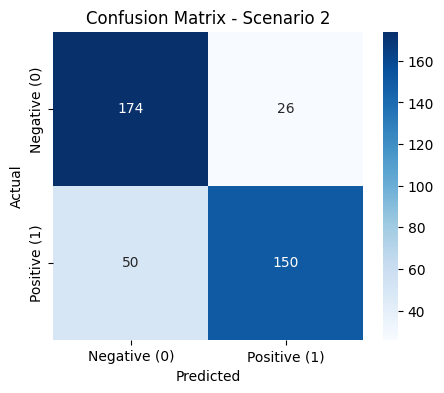

In [68]:
cm = np.array([[matrix[(0,0)], matrix[(0,1)]],
               [matrix[(1,0)], matrix[(1,1)]]])

plt.figure(figsize=(5, 4))
sns.heatmap(cm, annot=True, fmt="d", cmap="Blues",
            xticklabels=["Negative (0)", "Positive (1)"],
            yticklabels=["Negative (0)", "Positive (1)"])
plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.title("Confusion Matrix - Scenario 2")
plt.show()

###Scenario 3: With lemmatization and removal of stop words

In [66]:
train_scenario_3 = train_samples.copy()
test_scenario_3 = test_samples.copy()

In [67]:
train_scenario_3["clean_text"] = train_samples["text"].apply(
    lambda x: preprocess_text(x, lemmatize_words=True,
                                  remove_stop_words=True,
                                  handle_logical_negation=False)
)

In [69]:
test_scenario_3["clean_text"] = test_samples["text"].apply(
    lambda x: preprocess_text(x, lemmatize_words=True,
                                  remove_stop_words=True,
                                  handle_logical_negation=False)
)

In [88]:
train_scenario_3['clean_text'].iloc[0]

'similarity ray lawrence jindabyne movie lantana dead body repercussion dysfunctional life lantana offer hope resolution jindabyne leave unresolved bleak way leave viewer unsatisfie cheat storyline aftermath fisherman discovery corpse float remote river base short story raymond carver element robert altman classic 1993 ensemble short cut lawrence use theme exploration exposition relationship small australian community stress movie pose moral question let discovery dead body ruin good weekend poignantly australians difference dead person aboriginal acting especially gabriel byrne laura linney commendable element mysticism reinforce haunt music unlike picnic hanging rock sound like basis great movie prepare let pace slow murder show near beginning eliminate element mystery leave desolate life blank finale'

In [70]:
priors, word_counts, class_totals, vocab = train_naive_bayes(train_scenario_3, text_col="clean_text", label_col="label")

In [71]:
test_scenario_3["predicted"] = test_scenario_3["clean_text"].apply(
    lambda x: predict(x, priors, word_counts, class_totals, vocab)
)

In [72]:
matrix, metrics = evaluate(test_scenario_3['label'], test_scenario_3['predicted'], [0,1])

Confusion Matrix (rows=actual, cols=predicted)
        pred=0  pred=1
actual=0  167  33
actual=1  43  157

Class 0: precision=0.795  recall=0.835  f1=0.815
Class 1: precision=0.826  recall=0.785  f1=0.805

Overall accuracy: 0.810


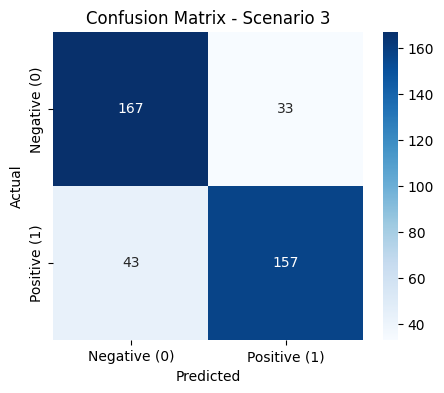

In [73]:
cm = np.array([[matrix[(0,0)], matrix[(0,1)]],
               [matrix[(1,0)], matrix[(1,1)]]])

plt.figure(figsize=(5, 4))
sns.heatmap(cm, annot=True, fmt="d", cmap="Blues",
            xticklabels=["Negative (0)", "Positive (1)"],
            yticklabels=["Negative (0)", "Positive (1)"])
plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.title("Confusion Matrix - Scenario 3")
plt.show()

###Scenario 4: With lemmatization, removal of stop words, and handling logical negation

In [74]:
train_scenario_4 = train_samples.copy()
test_scenario_4 = test_samples.copy()

In [75]:
train_scenario_4["clean_text"] = train_samples["text"].apply(
    lambda x: preprocess_text(x, lemmatize_words=True,
                                  remove_stop_words=True,
                                  handle_logical_negation=True)
)

In [76]:
test_scenario_4["clean_text"] = test_samples["text"].apply(
    lambda x: preprocess_text(x, lemmatize_words=True,
                                  remove_stop_words=True,
                                  handle_logical_negation=True)
)

In [89]:
train_scenario_4['clean_text'].iloc[0]

'similarity ray lawrence jindabyne movie lantana dead body repercussion dysfunctional life lantana offer hope resolution jindabyne leave unresolved bleak way leave viewer unsatisfie cheat storyline aftermath fisherman discovery corpse float remote river base short story raymond carver element robert altman classic 1993 ensemble short cut lawrence use theme exploration exposition relationship small australian community stress movie pose moral question let discovery dead body ruin good weekend poignantly australians difference dead person aboriginal acting especially gabriel byrne laura linney commendable element mysticism reinforce haunt music NOT_unlike picnic hanging rock sound like basis great movie prepare let pace slow murder show near beginning eliminate element mystery leave desolate life blank finale'

In [77]:
priors, word_counts, class_totals, vocab = train_naive_bayes(train_scenario_4, text_col="clean_text", label_col="label")

In [78]:
test_scenario_4["predicted"] = test_scenario_4["clean_text"].apply(
    lambda x: predict(x, priors, word_counts, class_totals, vocab)
)

In [79]:
matrix, metrics = evaluate(test_scenario_4['label'], test_scenario_4['predicted'], [0,1])

Confusion Matrix (rows=actual, cols=predicted)
        pred=0  pred=1
actual=0  169  31
actual=1  42  158

Class 0: precision=0.801  recall=0.845  f1=0.822
Class 1: precision=0.836  recall=0.790  f1=0.812

Overall accuracy: 0.818


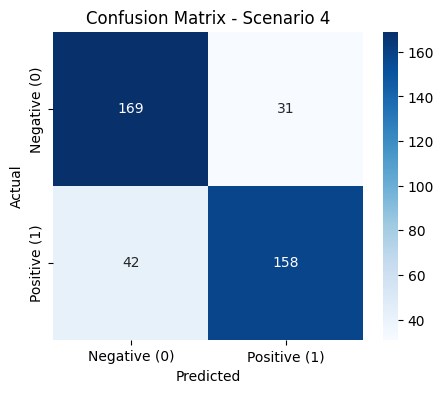

In [80]:
cm = np.array([[matrix[(0,0)], matrix[(0,1)]],
               [matrix[(1,0)], matrix[(1,1)]]])

plt.figure(figsize=(5, 4))
sns.heatmap(cm, annot=True, fmt="d", cmap="Blues",
            xticklabels=["Negative (0)", "Positive (1)"],
            yticklabels=["Negative (0)", "Positive (1)"])
plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.title("Confusion Matrix - Scenario 4")
plt.show()

###Trying without laplace smoothing

In [24]:
def predict_without_laplace(text, priors, word_counts, class_totals, vocab):
    # removes any unknown words.
    words = [w for w in text.split() if w in vocab]
    V = len(vocab)

    scores = {}
    for c in priors:
        log_prob = math.log(priors[c])
        for w in words:
            count = word_counts[c][w]  # 0 if unseen for this class
            # no laplace smoothing here
            likelihood = (count) / (class_totals[c] + V)
            log_prob += math.log(likelihood)
        scores[c] = log_prob

    return max(scores, key=scores.get)

In [18]:
train_scenario_5 = train_samples.copy()
test_scenario_5 = test_samples.copy()

In [19]:
train_scenario_5["clean_text"] = train_samples["text"].apply(
    lambda x: preprocess_text(x, lemmatize_words=True,
                                  remove_stop_words=True,
                                  handle_logical_negation=True)
)

In [20]:
test_scenario_5["clean_text"] = test_samples["text"].apply(
    lambda x: preprocess_text(x, lemmatize_words=True,
                                  remove_stop_words=True,
                                  handle_logical_negation=True)
)

In [21]:
priors, word_counts, class_totals, vocab = train_naive_bayes(train_scenario_5, text_col="clean_text", label_col="label")

In [20]:
test_scenario_5["predicted"] = test_scenario_5["clean_text"].apply(
    lambda x: predict_without_laplace(x, priors, word_counts, class_totals, vocab)
)

NameError: name 'test_scenario_5' is not defined

In [19]:
# checking that the labels for the first test scenario that were misclassified, what the actual text was.
misclassified = test_scenario_1[test_scenario_1["predicted"] != test_scenario_1["label"]]
for _, row in misclassified.head(3).iterrows():
    print(f"Original  : {row['text']}")
    print(f"Clean     : {row['clean_text']}")
    print(f"Actual    : {row['label']}")
    print(f"Predicted : {row['predicted']}")
    print("-" * 50)

Original  : What was Franco Zeffirelli thinking? Was Hollywood responsible for this travesty, or can I take comfort in the idea that someone who didn't speak English as a first language just completely missed the point of Charlotte Bronte's classic? I don't think I can improve on a comment I read below, so I'll just paraphrase it: "Jane Eyre is a great great book, the screenwriter should read it sometime." It's true that this movie's two leads were sadly miscast. But pity the actors, because the screenwriter left out all of the best scenes. The dialog that makes you understand the Jane and Rochester have a meeting of minds and a shared sense of fun...deleted from the script. The marriage proposal, the fortune teller...gone. The allusions, half joking, half sincerely felt, to Jane as a fairy sprite from olde England come to rescue Rochester in his despair...eliminated.<br /><br />It is unfortunate that Zeffirelli felt the need to completely rewrite the end of the novel and Jane's intera